In [9]:

# ============================================================
# ASD NEUROPIXELS REANALYSIS — ENVIRONMENT SETUP
# Run this cell once after every Colab runtime restart.
# ============================================================

# 1. Install required packages
%pip -q install one-api ibllib iblatlas numpy pandas scipy matplotlib seaborn scikit-learn statsmodels h5py pyarrow openpyxl tqdm psutil

# 2. Standard libraries
import os
import gc
import sys
import json
import time
import warnings
from pathlib import Path
from collections import defaultdict

# 3. Scientific computing
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Statistics and utilities
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from tqdm.auto import tqdm
import psutil

# 5. IBL / Neuropixels
from one.api import ONE
from brainbox.io.one import SpikeSortingLoader
from iblatlas.regions import BrainRegions

# 6. Google Drive
from google.colab import drive

drive.mount("/content/drive")

# 7. Project directories
ROOT = Path(
    "/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis"
)

DOCS = ROOT / "00_documentation"
NOTEBOOKS = ROOT / "01_notebooks"
META = ROOT / "02_session_metadata"
OUTPUT = ROOT / "03_processed_data"
RESULTS = ROOT / "04_results"
FIGURES = ROOT / "05_figures"

for folder in [DOCS, NOTEBOOKS, META, OUTPUT, RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

# 8. IBL connection
one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

# 9. Anatomical reference
atlas = pd.read_csv(META / "allen_region_dictionary.csv")
inventory = pd.read_csv(META / "mouse_probe_inventory.csv")

region_map = dict(
    zip(atlas["allen_acronym"], atlas["analysis_region"])
)

valid_regions = set(atlas["allen_acronym"])
brain_regions = BrainRegions()

# 10. Display and plotting defaults
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

sns.set_theme(style="ticks", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

# 11. Environment summary
print("=" * 55)
print("ASD NEUROPIXELS REANALYSIS — READY")
print("=" * 55)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("IBL connection:", one.alyx.base_url)
print("Project:", ROOT)
print("Animals:", inventory.subject.nunique())
print("Insertions:", len(inventory))
print("Anatomical labels:", len(atlas))
print("RAM available:",
      round(psutil.virtual_memory().available / 1024**3, 2),
      "GB")
print("Disk available:",
      round(psutil.disk_usage("/content").free / 1024**3, 2),
      "GB")
print("=" * 55)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ASD NEUROPIXELS REANALYSIS — READY
Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
IBL connection: https://openalyx.internationalbrainlab.org
Project: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis
Animals: 62
Insertions: 364
Anatomical labels: 24
RAM available: 11.01 GB
Disk available: 105.84 GB


In [20]:

# Find an existing WT insertion CSV and match it to the inventory.

WT_DIR = ROOT / "03_processed_data" / "WT"

print("WT directory:", WT_DIR)
print("Directory exists:", WT_DIR.exists())

files = list(WT_DIR.glob("*.csv"))

print("CSV files found:", len(files))
print("First files:", [p.name for p in files[:5]])

wt_inventory = inventory.loc[
    inventory["genotype"] == "WT"
].copy()

file_lookup = {
    p.stem: p
    for p in files
    if p.stem not in {
        "WT_all_neurons",
        "WT_region_summary",
        "processing_log"
    }
}

candidates = wt_inventory.loc[
    wt_inventory["pid"].astype(str).isin(file_lookup)
]

if candidates.empty:
    raise RuntimeError(
        "No matching insertion CSVs. Check the printed path and filenames."
    )

pilot = next(candidates.itertuples(index=False))
original = pd.read_csv(file_lookup[str(pilot.pid)])

print("\nSelected insertion:", pilot.pid)
print("Mouse:", pilot.subject)
print("Neurons:", len(original))


WT directory: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT
Directory exists: True
CSV files found: 102
First files: ['processing_log.csv', 'a22254bc-9827-4a8c-9da8-65732791f734.csv', 'e9a7b3a6-92c8-4326-9fa1-e366bd11bd2e.csv', 'c3aa978c-7759-465e-84f1-cf02c3f3d11f.csv', '9df0b2a4-6c21-491b-b1ae-4b82cb1fb835.csv']

Selected insertion: a22254bc-9827-4a8c-9da8-65732791f734
Mouse: NYU-58
Neurons: 13


In [21]:

# ============================================================
# CELL 02 — LOGISI PILOT: ONE WT INSERTION
#
# Purpose:
# 1. Load existing neuron metrics.
# 2. Recalculate burst-related metrics.
# 3. Compare previous and revised results.
# 4. Preserve all original files.
#
# Method:
# LogISI based on Pasquale et al. (2010) and
# Cotterill & Eglen (2016).
#
# This is a pilot Python implementation.
# Full validation against the reference R implementation
# is required before overwriting the WT dataset.
# ============================================================


# ------------------------------------------------------------
# 1. Burst detection utilities
# ------------------------------------------------------------

def find_burst_runs(times, threshold, min_spikes=3):
    """Detect consecutive spikes connected by short ISIs."""

    isi = np.diff(times)
    short = (isi > 0) & (isi <= threshold)

    starts = np.flatnonzero(
        short & ~np.r_[False, short[:-1]]
    )

    ends = np.flatnonzero(
        short & ~np.r_[short[1:], False]
    ) + 1

    return [
        (int(s), int(e))
        for s, e in zip(starts, ends)
        if e - s + 1 >= min_spikes
    ]


def revised_logisi(times, max_core_isi=0.100, min_spikes=3):
    """
    Pilot logISI burst detection.

    Steps:
    - Build log10(ISI) histogram.
    - Smooth histogram density.
    - Identify an intraburst peak.
    - Find a separating valley using void parameter >= 0.7.
    - Detect burst cores at 100 ms when applicable.
    - Extend cores when the adaptive threshold is >100 ms.

    Returns:
        bursts, threshold_ms, method
    """

    times = np.sort(np.asarray(times, dtype=float))

    isi = np.diff(times)
    positive = isi[isi >= 0.001]

    if len(positive) < 4:
        return [], np.nan, "insufficient_ISI"

    log_ms = np.log10(positive * 1000)

    upper = max(1.1, np.ceil(log_ms.max()))
    edges = np.arange(0, upper + 0.1001, 0.1)

    counts, edges = np.histogram(log_ms, bins=edges)

    if counts.sum() == 0:
        return [], np.nan, "empty_histogram"

    density = counts / counts.sum()

    smoothed = sm.nonparametric.lowess(
        density,
        np.arange(len(density)),
        frac=0.05,
        return_sorted=False
    )

    peaks, _ = find_peaks(smoothed, distance=2)

    peak_ms = 10 ** edges[peaks]
    intraburst = peaks[peak_ms < 100]

    if len(intraburst) == 0:
        return [], np.nan, "no_intraburst_peak"

    first_peak = intraburst[
        np.argmax(smoothed[intraburst])
    ]

    threshold = None

    # Find the first subsequent peak separated by
    # a valley satisfying the void criterion.
    for second_peak in peaks[peaks > first_peak]:

        valley = first_peak + np.argmin(
            smoothed[first_peak:second_peak + 1]
        )

        denominator = np.sqrt(
            max(smoothed[first_peak], 0) *
            max(smoothed[second_peak], 0)
        )

        if denominator <= 0:
            continue

        void = 1 - smoothed[valley] / denominator

        if void >= 0.7:
            threshold = 10 ** edges[valley] / 1000
            break

    # No valid threshold: use 100 ms core detection.
    if threshold is None or threshold >= 1:

        bursts = find_burst_runs(
            times,
            max_core_isi,
            min_spikes
        )

        return bursts, max_core_isi * 1000, "core_100ms"

    # Adaptive threshold <= 100 ms.
    if threshold <= max_core_isi:

        bursts = find_burst_runs(
            times,
            threshold,
            min_spikes
        )

        return bursts, threshold * 1000, "adaptive"

    # Adaptive threshold between 100 ms and 1 second.
    # Find 100 ms cores first, then expand their boundaries.
    cores = find_burst_runs(
        times,
        max_core_isi,
        min_spikes
    )

    if not cores:
        return [], threshold * 1000, "no_cores"

    extended = find_burst_runs(
        times,
        threshold,
        min_spikes
    )

    selected = [
        (s, e)
        for s, e in extended
        if any(
            s <= core_end and e >= core_start
            for core_start, core_end in cores
        )
    ]

    return sorted(set(selected)), threshold * 1000, "extended"


# ------------------------------------------------------------
# 2. Calculate burst metrics
# ------------------------------------------------------------

def revised_burst_metrics(times, duration):
    """Calculate burst statistics for one neuron."""

    times = np.sort(np.asarray(times, dtype=float))

    bursts, threshold_ms, method = revised_logisi(times)

    result = {
        "logisi_threshold_ms": threshold_ms,
        "burst_rate_min": len(bursts) * 60 / duration,
        "burst_fraction_pct": 0.0,
        "burst_duration_ms": np.nan,
        "spikes_per_burst": np.nan,
        "intraburst_hz": np.nan,
        "interburst_interval_s": np.nan,
        "logisi_method": method,
        "n_bursts": len(bursts)
    }

    if not bursts:
        return result

    counts = np.array([
        e - s + 1
        for s, e in bursts
    ])

    durations = np.array([
        times[e] - times[s]
        for s, e in bursts
    ])

    result["burst_fraction_pct"] = (
        100 * counts.sum() / len(times)
    )

    result["burst_duration_ms"] = (
        1000 * durations.mean()
    )

    result["spikes_per_burst"] = counts.mean()

    valid = durations > 0

    if np.any(valid):
        result["intraburst_hz"] = np.mean(
            (counts[valid] - 1) / durations[valid]
        )

    if len(bursts) > 1:

        intervals = [
            times[bursts[j + 1][0]] - times[bursts[j][1]]
            for j in range(len(bursts) - 1)
        ]

        result["interburst_interval_s"] = np.mean(intervals)

    return result


# ------------------------------------------------------------
# 3. Find one existing WT insertion
# ------------------------------------------------------------

WT_DIR = ROOT / "03_processed_data" / "WT"

wt_inventory = inventory.loc[
    inventory["genotype"] == "WT"
].copy()

file_lookup = {
    p.stem: p
    for p in WT_DIR.glob("*.csv")
    if p.stem not in {
        "WT_all_neurons",
        "WT_region_summary",
        "processing_log"
    }
}

candidates = wt_inventory.loc[
    wt_inventory["pid"].astype(str).isin(file_lookup)
]

if candidates.empty:
    raise RuntimeError("No matching WT insertion CSV files found.")

# Select the first insertion containing neuronal data.
pilot = None
original = None

for rec in candidates.itertuples(index=False):
    candidate_data = pd.read_csv(file_lookup[str(rec.pid)])

    if "cluster_id" in candidate_data and len(candidate_data) > 0:
        pilot = rec
        original = candidate_data
        break

if pilot is None:
    raise RuntimeError("No non-empty WT insertion CSV found.")

print("=" * 55)
print("LOGISI PILOT")
print("=" * 55)
print("Mouse:", pilot.subject)
print("Insertion:", pilot.pid)
print("Existing neurons:", len(original))


# ------------------------------------------------------------
# 4. Load spike times from IBL cache / server
# ------------------------------------------------------------

loader = SpikeSortingLoader(
    pid=str(pilot.pid),
    one=one
)

spikes, clusters, channels = loader.load_spike_sorting()

spike_times = np.asarray(spikes["times"])
spike_clusters = np.asarray(spikes["clusters"])

duration = float(
    spike_times.max() - spike_times.min()
)

# Sort by cluster ID only once.
order = np.argsort(spike_clusters, kind="stable")

sorted_ids = spike_clusters[order]
sorted_times = spike_times[order]

cluster_ids, starts, counts = np.unique(
    sorted_ids,
    return_index=True,
    return_counts=True
)

ranges = {
    int(cid): (int(start), int(count))
    for cid, start, count in zip(
        cluster_ids, starts, counts
    )
}


# ------------------------------------------------------------
# 5. Recalculate bursting for all neurons in this insertion
# ------------------------------------------------------------

results = []

for row in original.itertuples(index=False):

    cid = int(row.cluster_id)

    if cid not in ranges:
        raise ValueError(f"Missing cluster ID: {cid}")

    start, count = ranges[cid]

    neuron_times = sorted_times[
        start:start + count
    ]

    metrics = revised_burst_metrics(
        neuron_times,
        duration
    )

    results.append({
        "cluster_id": cid,
        "region": row.original_region,

        "old_burst_rate": row.burst_rate_min,
        "new_burst_rate": metrics["burst_rate_min"],

        "old_burst_fraction": row.burst_fraction_pct,
        "new_burst_fraction": metrics["burst_fraction_pct"],

        "old_burst_duration": row.burst_duration_ms,
        "new_burst_duration": metrics["burst_duration_ms"],

        "old_spikes_per_burst": row.spikes_per_burst,
        "new_spikes_per_burst": metrics["spikes_per_burst"],

        "threshold_ms": metrics["logisi_threshold_ms"],
        "method": metrics["logisi_method"],
        "n_bursts": metrics["n_bursts"]
    })

comparison = pd.DataFrame(results)


# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n=== THRESHOLD METHODS ===")
display(comparison["method"].value_counts())

print("\n=== OLD VS NEW — MEAN VALUES ===")

metric_columns = [
    "old_burst_rate",
    "new_burst_rate",
    "old_burst_fraction",
    "new_burst_fraction",
    "old_burst_duration",
    "new_burst_duration",
    "old_spikes_per_burst",
    "new_spikes_per_burst"
]

display(
    comparison[metric_columns]
    .mean()
    .round(3)
    .to_frame("Mean")
)

print("\n=== INDIVIDUAL NEURONS ===")
display(comparison.round(3))

print("\n=== EXTREME VALUES ===")

print(
    "Maximum burst duration (ms):",
    round(comparison["new_burst_duration"].max(), 3)
)

print(
    "Maximum spikes per burst:",
    round(comparison["new_spikes_per_burst"].max(), 3)
)


# ------------------------------------------------------------
# 7. Free memory
# ------------------------------------------------------------

del spikes, clusters, channels
del spike_times, spike_clusters
del order, sorted_ids, sorted_times
del cluster_ids, starts, counts, ranges

gc.collect()

print("\n" + "=" * 55)
print("PILOT FINISHED — NO FILES OVERWRITTEN")
print("=" * 55)


LOGISI PILOT
Mouse: NYU-58
Insertion: a22254bc-9827-4a8c-9da8-65732791f734
Existing neurons: 13

=== THRESHOLD METHODS ===


,count
method,
core_100ms,8
extended,4
adaptive,1



=== OLD VS NEW — MEAN VALUES ===


,Mean
old_burst_rate,16.098
new_burst_rate,14.105
old_burst_fraction,66.867
new_burst_fraction,70.517
old_burst_duration,803.821
new_burst_duration,2484.270
old_spikes_per_burst,31.947
new_spikes_per_burst,64.211



=== INDIVIDUAL NEURONS ===


,cluster_id,region,old_burst_rate,new_burst_rate,old_burst_fraction,new_burst_fraction,old_burst_duration,new_burst_duration,old_spikes_per_burst,new_spikes_per_burst,threshold_ms,method,n_bursts
0,143,MRN,2.886,1.027,63.384,81.741,309.627,2111.030,7.281,26.389,501.187,extended,95
1,150,MRN,12.530,5.665,77.025,88.646,320.176,1468.546,9.985,25.418,501.187,extended,524
2,152,MRN,1.470,1.470,44.129,44.129,200.078,200.078,5.941,5.941,100.000,core_100ms,136
3,156,MRN,2.778,1.665,58.747,70.644,231.852,795.299,6.533,13.110,316.228,extended,154
4,158,MRN,0.000,0.011,0.000,0.025,NaN,12.533,NaN,3.000,7.943,adaptive,1
5,161,MRN,30.919,30.919,57.933,57.933,230.392,230.392,5.715,5.715,100.000,core_100ms,2860
6,162,MRN,18.735,18.735,98.201,98.201,1858.795,1858.795,128.794,128.794,100.000,core_100ms,1733
7,163,MRN,41.967,41.967,92.343,92.343,621.749,621.749,21.197,21.197,100.000,core_100ms,3882
8,169,MRN,32.011,32.011,82.264,82.264,307.210,307.210,8.692,8.692,100.000,core_100ms,2961
9,172,MRN,6.573,6.573,32.636,32.636,123.922,123.922,3.928,3.928,100.000,core_100ms,608



=== EXTREME VALUES ===
Maximum burst duration (ms): 19500.222
Maximum spikes per burst: 419.898

PILOT FINISHED — NO FILES OVERWRITTEN
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


Cluster: 183
Spikes: 20779
Threshold: 398.11 ms
Method: extended
Detected bursts: 49

LONGEST BURST
Duration: 308.064 s
Spikes: 7264
Mean intraburst ISI: 42.42 ms


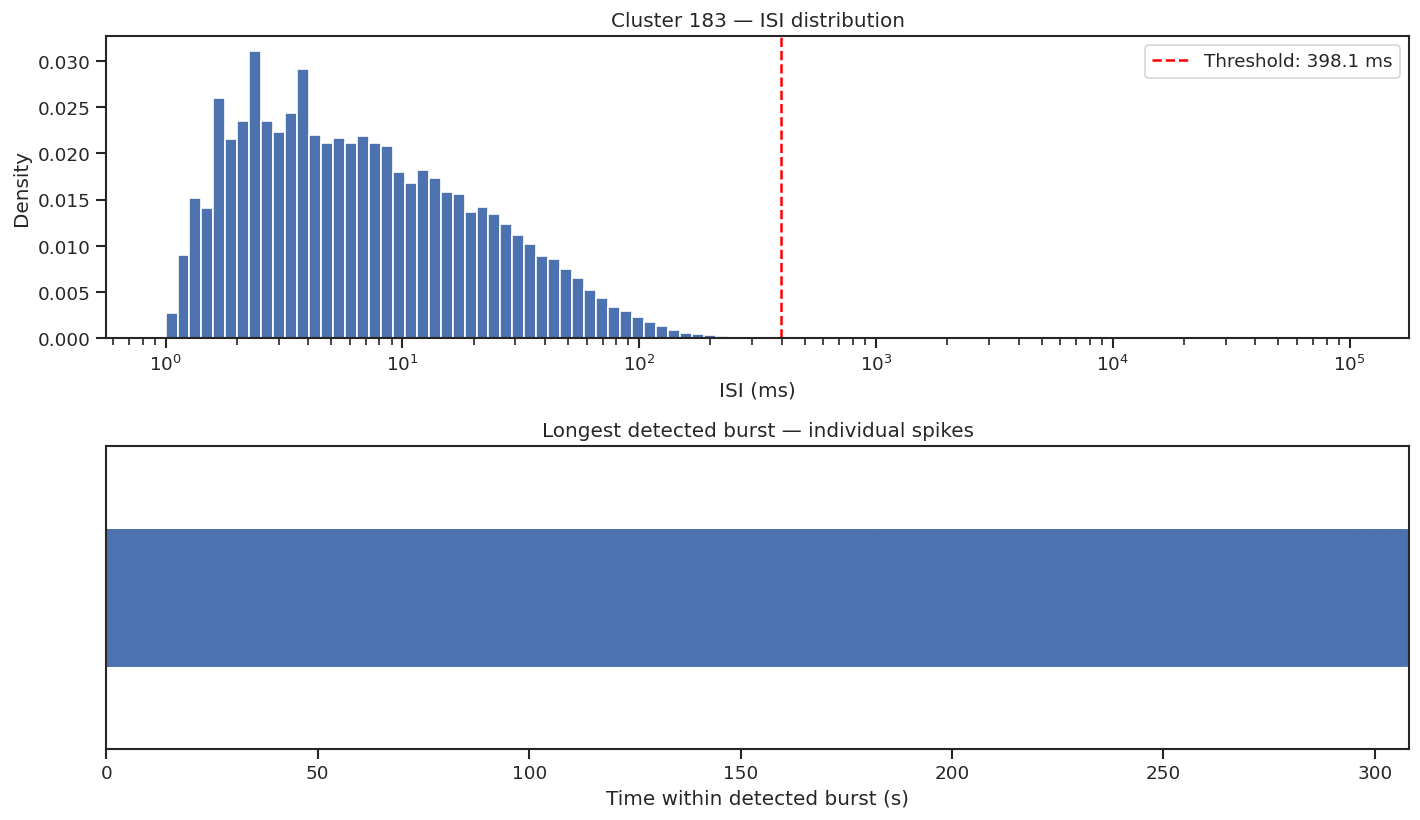

2408

In [22]:

# Inspect the spike train responsible for unusually long bursts.
# Diagnostic only — no files are modified.

loader = SpikeSortingLoader(pid=str(pilot.pid), one=one)
spikes, _, _ = loader.load_spike_sorting()

t = np.sort(
    np.asarray(spikes["times"])[
        np.asarray(spikes["clusters"]) == 183
    ]
)

bursts, threshold_ms, method = revised_logisi(t)
isi_ms = np.diff(t) * 1000

print("Cluster:", 183)
print("Spikes:", len(t))
print("Threshold:", round(threshold_ms, 2), "ms")
print("Method:", method)
print("Detected bursts:", len(bursts))

# Identify the longest detected burst.
s, e = max(bursts, key=lambda b: t[b[1]] - t[b[0]])

print("\nLONGEST BURST")
print("Duration:", round(t[e] - t[s], 3), "s")
print("Spikes:", e - s + 1)
print("Mean intraburst ISI:",
      round(np.diff(t[s:e + 1]).mean() * 1000, 2), "ms")

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# Logarithmic ISI distribution.
axes[0].hist(
    isi_ms[isi_ms > 0],
    bins=np.logspace(0, 5, 100),
    density=True
)
axes[0].axvline(
    threshold_ms,
    color="red",
    linestyle="--",
    label=f"Threshold: {threshold_ms:.1f} ms"
)
axes[0].set_xscale("log")
axes[0].set_xlabel("ISI (ms)")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].set_title("Cluster 183 — ISI distribution")

# Spike raster for the longest burst.
axes[1].eventplot(
    t[s:e + 1] - t[s],
    lineoffsets=0.5,
    linelengths=0.8
)
axes[1].set_xlim(0, t[e] - t[s])
axes[1].set_xlabel("Time within detected burst (s)")
axes[1].set_yticks([])
axes[1].set_title("Longest detected burst — individual spikes")

plt.tight_layout()
plt.show()

del spikes
gc.collect()


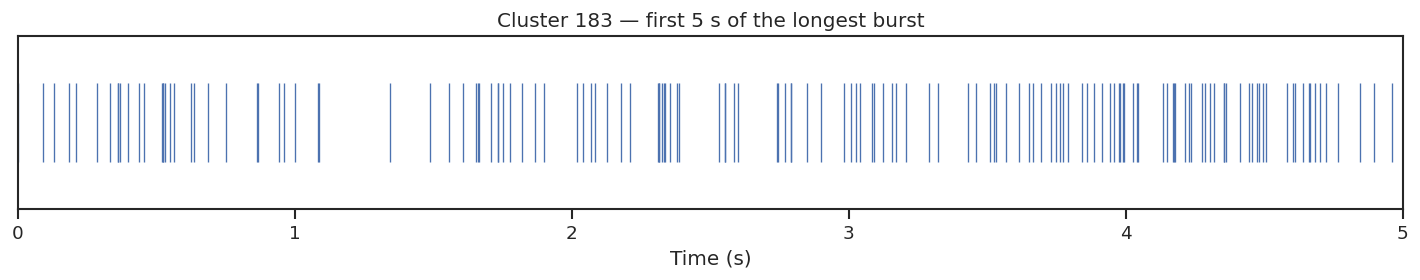

Spikes in 5 s: 148
Mean ISI (ms): 33.75
Median ISI (ms): 25.33
ISI > 100 ms (%): 5.44
ISI > 200 ms (%): 0.68


In [23]:

# Inspect a five-second segment of the longest detected burst.
# No files are modified.

segment_start = t[s]
segment_end = segment_start + 5.0

segment = t[
    (t >= segment_start) &
    (t < segment_end)
] - segment_start

segment_isi = np.diff(segment) * 1000

fig, ax = plt.subplots(figsize=(12, 2.5))

ax.eventplot(
    segment,
    lineoffsets=0.5,
    linelengths=0.8,
    linewidths=0.8
)

ax.set_xlim(0, 5)
ax.set_yticks([])
ax.set_xlabel("Time (s)")
ax.set_title("Cluster 183 — first 5 s of the longest burst")

plt.tight_layout()
plt.show()

print("Spikes in 5 s:", len(segment))
print("Mean ISI (ms):", round(np.mean(segment_isi), 2))
print("Median ISI (ms):", round(np.median(segment_isi), 2))
print("ISI > 100 ms (%):",
      round(100 * np.mean(segment_isi > 100), 2))
print("ISI > 200 ms (%):",
      round(100 * np.mean(segment_isi > 200), 2))


In [10]:



drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis")
META = ROOT / "02_session_metadata"
RESULTS = ROOT / "04_results"
RESULTS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(META / "recovered_24_eligible_regions.csv")

genotypes = ["WT", "Fmr1", "Cntnap2", "Shank3B"]

# Anatomically defined regions for the primary analysis.
region_groups = {
    "DG": ["DG-mo", "DG-sg", "DG-po"],
    "CA1": ["CA1"],
    "CA3": ["CA3"],
    "VISp": ["VISp2/3", "VISp4", "VISp5", "VISp6a", "VISp6b"],
    "MOs": ["MOs2/3", "MOs5", "MOs6a"],
    "CP": ["CP"],
    "SUB": ["SUB"],
    "VL": ["VL"],
    "MRN": ["MRN"],
    "APN": ["APN"],
}

# Parent atlas labels and white-matter structures.
excluded_regions = ["HPF", "STR", "MB", "ccb", "cing", "dhc"]

records = []

for group, regions in region_groups.items():
    subset = df[df["region"].isin(regions)]

    row = {
        "region_group": group,
        "subregions": ", ".join(regions),
        "n_subregions": len(subset)
    }

    for genotype in genotypes:
        animals = subset[f"{genotype}_animals"]
        units = subset[f"{genotype}_units"]
        events = subset[f"{genotype}_complete_event_mice"]

        # Without mouse IDs, the exact union across
        # subregions cannot be calculated.
        row[f"{genotype}_mice_lower_bound"] = int(animals.max())
        row[f"{genotype}_units"] = int(units.sum())
        row[f"{genotype}_event_mice_lower_bound"] = int(events.max())

    row["min_mice_lower_bound"] = min(
        row[f"{g}_mice_lower_bound"] for g in genotypes
    )

    row["min_event_mice_lower_bound"] = min(
        row[f"{g}_event_mice_lower_bound"] for g in genotypes
    )

    records.append(row)

grouped = pd.DataFrame(records).sort_values(
    "min_mice_lower_bound", ascending=False
)

grouped["eligible_all_genotypes"] = (
    grouped["min_mice_lower_bound"] >= 5
)

# Save the new analysis matrix permanently.
grouped.to_csv(
    RESULTS / "anatomical_group_coverage.csv",
    index=False
)

df[df["region"].isin(excluded_regions)].to_csv(
    RESULTS / "excluded_atlas_labels.csv",
    index=False
)

display_cols = (
    ["region_group"]
    + [f"{g}_mice_lower_bound" for g in genotypes]
    + [f"{g}_units" for g in genotypes]
    + ["min_event_mice_lower_bound"]
)

print("ANATOMICAL GROUP COVERAGE")
display(grouped[display_cols])

print("\nELIGIBLE GROUPS:")
print(grouped.loc[
    grouped["eligible_all_genotypes"], "region_group"
].tolist())

print("\nSaved to:", RESULTS / "anatomical_group_coverage.csv")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ANATOMICAL GROUP COVERAGE


,region_group,WT_mice_lower_bound,Fmr1_mice_lower_bound,Cntnap2_mice_lower_bound,Shank3B_mice_lower_bound,WT_units,Fmr1_units,Cntnap2_units,Shank3B_units,min_event_mice_lower_bound
0,DG,15,13,13,13,1654,2592,865,1552,12
1,CA1,13,11,11,14,1134,1495,1117,1879,11
2,CA3,11,10,10,9,568,324,771,666,8
4,MOs,12,12,8,7,1096,1519,986,979,6
5,CP,9,10,7,6,822,890,807,1070,5
8,MRN,9,11,6,7,2033,1136,1280,796,6
3,VISp,13,11,5,9,1285,1174,594,1039,5
6,SUB,8,10,6,5,808,1293,681,797,5
7,VL,7,8,5,7,131,154,172,567,5
9,APN,7,10,5,7,622,1000,314,586,5



ELIGIBLE GROUPS:
['DG', 'CA1', 'CA3', 'MOs', 'CP', 'MRN', 'VISp', 'SUB', 'VL', 'APN']

Saved to: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/04_results/anatomical_group_coverage.csv


In [11]:

from pathlib import Path

folders = [
    Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis"),
    Path("/content/autism_anatomy_inventory"),
]

target_files = {
    "insertion_region_details.csv",
    "region_genotype_details.csv",
    "region_genotype_matrix.csv",
}

for folder in folders:
    print(f"\nChecking: {folder}")
    if not folder.exists():
        print("Not found")
        continue

    found = [
        p for p in folder.rglob("*.csv")
        if p.name in target_files
    ]

    for p in found:
        print("FOUND:", p)

    if not found:
        print("No detailed inventory files found")



Checking: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis
No detailed inventory files found

Checking: /content/autism_anatomy_inventory
Not found


In [12]:

import pandas as pd
from pathlib import Path
from io import StringIO

ROOT = Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis")
META = ROOT / "02_session_metadata"
DOCS = ROOT / "00_documentation"

META.mkdir(parents=True, exist_ok=True)
DOCS.mkdir(parents=True, exist_ok=True)

# Allen CCFv3 anatomical region dictionary.
region_text = """allen_acronym|full_name|macro_system|analysis_region|analysis_status
DG-mo|Dentate gyrus, molecular layer|Hippocampal formation|DG|include
DG-sg|Dentate gyrus, granule cell layer|Hippocampal formation|DG|include
DG-po|Dentate gyrus, polymorph layer|Hippocampal formation|DG|include
CA1|Field CA1|Hippocampal formation|CA1|include
CA3|Field CA3|Hippocampal formation|CA3|include
SUB|Subiculum|Hippocampal formation|SUB|include
VISp2/3|Primary visual area, layer 2/3|Cerebral cortex|VISp|include
VISp4|Primary visual area, layer 4|Cerebral cortex|VISp|include
VISp5|Primary visual area, layer 5|Cerebral cortex|VISp|include
VISp6a|Primary visual area, layer 6a|Cerebral cortex|VISp|include
VISp6b|Primary visual area, layer 6b|Cerebral cortex|VISp|include
MOs2/3|Secondary motor area, layer 2/3|Cerebral cortex|MOs|include
MOs5|Secondary motor area, layer 5|Cerebral cortex|MOs|include
MOs6a|Secondary motor area, layer 6a|Cerebral cortex|MOs|include
CP|Caudoputamen (dorsal striatum)|Striatum|CP|include
MRN|Midbrain reticular nucleus|Midbrain|MRN|include
APN|Anterior pretectal nucleus|Midbrain|APN|include
HPF|Hippocampal formation, unspecified|Unresolved parent label|UNRESOLVED_HPF|exclude_primary
STR|Striatum, unspecified|Unresolved parent label|UNRESOLVED_STR|exclude_primary
MB|Midbrain, unspecified|Unresolved parent label|UNRESOLVED_MB|exclude_primary
VL|Lateral ventricle|Ventricular system|NON_NEURAL|exclude
ccb|Corpus callosum, body|Fiber tracts|NON_NEURAL|exclude
cing|Cingulum bundle|Fiber tracts|NON_NEURAL|exclude
dhc|Dorsal hippocampal commissure|Fiber tracts|NON_NEURAL|exclude
"""

atlas = pd.read_csv(StringIO(region_text), sep="|")

# Save the anatomical dictionary.
atlas.to_csv(META / "allen_region_dictionary.csv", index=False)

# Read the previously recovered region counts.
coverage = pd.read_csv(
    META / "recovered_24_eligible_regions.csv"
)

# Attach region labels without changing original counts.
annotated = coverage.merge(
    atlas,
    left_on="region",
    right_on="allen_acronym",
    how="left",
    validate="one_to_one"
)

annotated.to_csv(
    META / "annotated_region_coverage.csv",
    index=False
)

# Save the analysis plan.
plan = """# Electrophysiological reanalysis plan

Dataset: angelaki_mouseASD
Genotypes: WT, Fmr1, Cntnap2, Shank3B

Primary neuronal regions:
DG, CA1, CA3, SUB, VISp, MOs, CP, MRN, APN.

1. Recover mouse/session/probe/cluster identifiers and Allen labels.
2. Merge anatomical sublayers at the individual-cluster level.
3. Select QC-pass neuronal units and report unique mouse coverage.
4. Calculate firing rate, ISI CV and CV2.
5. Quantify bursting and pause characteristics.
6. Analyze stimulus-, movement- and feedback-aligned activity.
7. Compare each ASD genotype with WT.
8. Assess shared and genotype-specific abnormalities.

Statistics:
Mouse is the biological replicate.
Retain neuron, probe and session identifiers.
Report effect sizes, confidence intervals and adjusted p-values.
Apply multiple-comparison correction to confirmatory tests.

Important:
VL denotes lateral ventricle, not ventrolateral thalamus.
White matter and unspecified parent regions are excluded
from primary neuronal comparisons.

All long computations must save checkpoints to Google Drive.
"""

(DOCS / "ANALYSIS_PLAN.md").write_text(plan, encoding="utf-8")

print("Saved anatomical dictionary:", len(atlas), "labels")
print("Primary neuronal regions:",
      atlas.loc[atlas.analysis_status == "include",
                "analysis_region"].nunique())
print("Saved annotated coverage and analysis plan.")

display(atlas)


Saved anatomical dictionary: 24 labels
Primary neuronal regions: 9
Saved annotated coverage and analysis plan.


,allen_acronym,full_name,macro_system,analysis_region,analysis_status
0,DG-mo,"Dentate gyrus, molecular layer",Hippocampal formation,DG,include
1,DG-sg,"Dentate gyrus, granule cell layer",Hippocampal formation,DG,include
2,DG-po,"Dentate gyrus, polymorph layer",Hippocampal formation,DG,include
3,CA1,Field CA1,Hippocampal formation,CA1,include
4,CA3,Field CA3,Hippocampal formation,CA3,include
5,SUB,Subiculum,Hippocampal formation,SUB,include
6,VISp2/3,"Primary visual area, layer 2/3",Cerebral cortex,VISp,include
7,VISp4,"Primary visual area, layer 4",Cerebral cortex,VISp,include
8,VISp5,"Primary visual area, layer 5",Cerebral cortex,VISp,include
9,VISp6a,"Primary visual area, layer 6a",Cerebral cortex,VISp,include


In [13]:



from one.api import ONE

ROOT = Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis")
META = ROOT / "02_session_metadata"
META.mkdir(parents=True, exist_ok=True)

one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

# Retrieve probe insertions belonging to the ASD dataset.
insertions = one.alyx.rest(
    "insertions",
    "list",
    django="session__projects__name,angelaki_mouseASD"
)

records = []

for insertion in insertions:
    session = insertion.get("session")
    if not isinstance(session, dict):
        continue

    subject = session.get("subject", "")
    if isinstance(subject, dict):
        subject = subject.get("nickname", "")

    subject = str(subject)
    prefix = subject.split("-")[0].upper()

    genotype = {
        "NYU": "WT",
        "FMR": "Fmr1",
        "CSP": "Cntnap2",
        "SH": "Shank3B"
    }.get(prefix)

    if genotype is None:
        continue

    records.append({
        "pid": insertion["id"],
        "eid": session["id"],
        "probe": insertion.get("name"),
        "subject": subject,
        "genotype": genotype
    })

inventory = pd.DataFrame(
    records,
    columns=["pid", "eid", "probe", "subject", "genotype"]
).drop_duplicates(subset=["pid"])

inventory.to_csv(META / "mouse_probe_inventory.csv", index=False)

print("Total probe insertions:", len(inventory))
print("Unique mice:", inventory["subject"].nunique())
display(inventory.groupby("genotype").agg(
    mice=("subject", "nunique"),
    probes=("pid", "nunique")
))
print("Saved:", META / "mouse_probe_inventory.csv")


Total probe insertions: 0
Unique mice: 0


,mice,probes
genotype,,


Saved: /content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/02_session_metadata/mouse_probe_inventory.csv


In [14]:
ROOT = Path("/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis")
META = ROOT / "02_session_metadata"

one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

project = "angelaki_mouseASD"

# Retrieve all insertions and sessions from the project.
insertions = one.alyx.rest(
    "insertions", "list",
    django=f"session__projects__name,{project}"
)

sessions = one.alyx.rest(
    "sessions", "list",
    django=f"projects__name,{project}"
)

def get_id(value):
    if isinstance(value, dict):
        value = value.get("id", "")
    return str(value).rstrip("/").split("/")[-1]

# Match session UUIDs with subject information.
session_lookup = {
    get_id(s["id"]): s for s in sessions
}

genotype_map = {
    "NYU": "WT",
    "FMR": "Fmr1",
    "CSP": "Cntnap2",
    "SH": "Shank3B"
}

records = []

for ins in insertions:
    eid = get_id(ins.get("session"))
    session = session_lookup.get(eid)

    if session is None:
        continue

    subject = session.get("subject", "")
    if isinstance(subject, dict):
        subject = subject.get("nickname", "")

    subject = str(subject)
    genotype = genotype_map.get(subject.split("-")[0].upper())

    if genotype is None:
        continue

    records.append({
        "pid": ins["id"],
        "eid": eid,
        "probe": ins.get("name"),
        "subject": subject,
        "genotype": genotype
    })

inventory = pd.DataFrame(
    records,
    columns=["pid", "eid", "probe", "subject", "genotype"]
).drop_duplicates("pid")

# Never overwrite the saved inventory with an empty result.
if inventory.empty:
    raise RuntimeError(
        f"No matching insertions. "
        f"Insertions returned: {len(insertions)}, "
        f"sessions returned: {len(sessions)}."
    )

inventory.to_csv(
    META / "mouse_probe_inventory.csv",
    index=False
)

print("Total insertions:", len(inventory))
print("Unique mice:", inventory.subject.nunique())

display(
    inventory.groupby("genotype").agg(
        mice=("subject", "nunique"),
        insertions=("pid", "nunique")
    )
)

print("Inventory saved successfully.")


Total insertions: 99
Unique mice: 15


,mice,insertions
genotype,,
WT,15,99


Inventory saved successfully.


In [15]:

# Restore genotype assignments from the original behavioral lists.

BEHAVIOUR = ROOT.parent / "Behaviour"

source_files = {
    "WT": "behavior_list_NYU.xlsx",
    "Fmr1": "behavior_list_FMR.xlsx",
    "Cntnap2": "behavior_list_CSP.xlsx",
    "Shank3B": "behavior_list_SH.xlsx",
}

subject_to_genotype = {}

for genotype, filename in source_files.items():
    sheet = pd.read_excel(BEHAVIOUR / filename, header=None)

    # Animal identifiers are in the first column.
    subjects = (
        sheet.iloc[:, 0]
        .dropna()
        .astype(str)
        .str.strip()
    )

    for subject in subjects:
        if subject in subject_to_genotype:
            if subject_to_genotype[subject] != genotype:
                raise ValueError(
                    f"Conflicting genotype assignment: {subject}"
                )
        subject_to_genotype[subject] = genotype

    print(f"{genotype}: {subjects.nunique()} listed animals")

# Use the complete Alyx session list retrieved previously.
session_lookup = {
    get_id(s["id"]): s for s in sessions
}

records = []

for ins in insertions:
    eid = get_id(ins.get("session"))
    session = session_lookup.get(eid)

    if session is None:
        continue

    subject = session.get("subject", "")

    if isinstance(subject, dict):
        subject = subject.get("nickname", "")

    subject = str(subject).strip()
    genotype = subject_to_genotype.get(subject)

    if genotype is None:
        continue

    records.append({
        "pid": ins["id"],
        "eid": eid,
        "probe": ins.get("name"),
        "subject": subject,
        "genotype": genotype
    })

full_inventory = pd.DataFrame(records).drop_duplicates("pid")

summary = full_inventory.groupby("genotype").agg(
    mice=("subject", "nunique"),
    insertions=("pid", "nunique")
).reindex(["WT", "Fmr1", "Cntnap2", "Shank3B"])

print("\nRESTORED DATASET")
display(summary)

print("Total insertions:", len(full_inventory))
print("Unique mice:", full_inventory.subject.nunique())

# Save only if all four genotypes were recovered.
if full_inventory.genotype.nunique() == 4:
    full_inventory.to_csv(
        META / "mouse_probe_inventory.csv",
        index=False
    )
    print("Full inventory saved.")
else:
    print("Incomplete matching — previous inventory preserved.")
    print("Unmatched session subjects:")
    unmatched = sorted({
        str(s.get("subject", ""))
        for s in sessions
        if str(s.get("subject", "")) not in subject_to_genotype
    })
    print(unmatched[:30])


WT: 15 listed animals
Fmr1: 25 listed animals
Cntnap2: 25 listed animals
Shank3B: 22 listed animals

RESTORED DATASET


,mice,insertions
genotype,,
WT,15,99
Fmr1,15,105
Cntnap2,16,85
Shank3B,16,75


Total insertions: 364
Unique mice: 62
Full inventory saved.


In [16]:

!echo "=== DISK ==="
!df -h /content

!echo "=== RAM ==="
!free -h

!echo "=== IBL CACHE ==="
!du -sh /root/Downloads/ONE 2>/dev/null


=== DISK ===
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G  1.9G  106G   2% /
=== RAM ===
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.8Gi       6.8Gi       5.0Mi       4.4Gi        10Gi
Swap:             0B          0B          0B
=== IBL CACHE ===
1.3G	/root/Downloads/ONE


In [17]:

# WT analysis: all insertions, 24 original regions.
# Each insertion is checkpointed immediately to Google Drive.

OUTPUT = ROOT / "03_processed_data" / "WT"
OUTPUT.mkdir(parents=True, exist_ok=True)

WT = pd.read_csv(META / "mouse_probe_inventory.csv")
WT = WT.loc[WT["genotype"] == "WT"].copy()

atlas = pd.read_csv(META / "allen_region_dictionary.csv")
region_map = atlas.set_index("allen_acronym")["analysis_region"].to_dict()
valid_regions = set(atlas["allen_acronym"])

assert WT.subject.nunique() == 15
assert len(WT) == 99

# LogISI burst detection: individual ISI distributions.
# Pasquale et al. (2010); Cotterill et al. (2016).
def logisi_bursts(t, max_isi=0.100, min_spikes=3):
    isi = np.diff(t)
    positive = isi[isi > 0]

    if len(positive) < 3:
        return [], np.nan

    log_values = np.log10(positive * 1000)
    edges = np.arange(
        np.floor(log_values.min() * 10) / 10,
        np.ceil(log_values.max() * 10) / 10 + 0.11,
        0.1
    )
    if len(edges) < 4:
        return [], np.nan

    counts, edges = np.histogram(log_values, bins=edges)
    centers = (edges[:-1] + edges[1:]) / 2
    smooth = np.convolve(counts, np.ones(3) / 3, mode="same")

    peaks, _ = find_peaks(smooth)
    early = peaks[(10 ** centers[peaks]) <= max_isi * 1000]

    if len(early) == 0:
        return [], np.nan

    first = early[np.argmax(smooth[early])]
    cutoff = max_isi

    for second in peaks[peaks > first]:
        valley = first + np.argmin(smooth[first:second + 1])
        denominator = np.sqrt(smooth[first] * smooth[second])

        if denominator <= 0:
            continue

        void = 1 - smooth[valley] / denominator

        if void > 0.7:
            cutoff = min(10 ** centers[valley] / 1000, max_isi)
            break

    short = (isi > 0) & (isi < cutoff)

    starts = np.flatnonzero(
        short & ~np.r_[False, short[:-1]]
    )
    ends = np.flatnonzero(
        short & ~np.r_[short[1:], False]
    ) + 1

    bursts = [
        (int(s), int(e))
        for s, e in zip(starts, ends)
        if e - s + 1 >= min_spikes
    ]

    return bursts, cutoff * 1000


def compute_metrics(t, duration):
    t = np.sort(np.asarray(t, dtype=float))
    isi = np.diff(t)
    positive = isi[isi > 0]
    bursts, threshold = logisi_bursts(t)

    result = {
        "n_spikes": len(t),
        "fr_hz": len(t) / duration,
        "mean_isi_ms": np.mean(positive) * 1000
            if len(positive) else np.nan,
        "cv_isi": np.std(positive) / np.mean(positive)
            if len(positive) >= 3 else np.nan,
        "cv2": np.mean(
            2 * np.abs(np.diff(positive)) /
            (positive[:-1] + positive[1:])
        ) if len(positive) >= 3 else np.nan,
        "logisi_threshold_ms": threshold,
        "burst_rate_min": len(bursts) * 60 / duration,
        "burst_fraction_pct": 0.0,
        "burst_duration_ms": np.nan,
        "spikes_per_burst": np.nan,
        "intraburst_hz": np.nan,
        "interburst_interval_s": np.nan,
    }

    if bursts:
        counts = np.array([e - s + 1 for s, e in bursts])
        lengths = np.array([t[e] - t[s] for s, e in bursts])

        result["burst_fraction_pct"] = (
            100 * counts.sum() / len(t)
        )
        result["burst_duration_ms"] = 1000 * lengths.mean()
        result["spikes_per_burst"] = counts.mean()
        result["intraburst_hz"] = np.mean(
            (counts - 1) / lengths
        )

        if len(bursts) > 1:
            gaps = [
                t[bursts[i + 1][0]] - t[bursts[i][1]]
                for i in range(len(bursts) - 1)
            ]
            result["interburst_interval_s"] = np.mean(gaps)

    return result


def process_insertion(rec):
    loader = SpikeSortingLoader(pid=str(rec.pid), one=one)
    spikes, clusters, channels = loader.load_spike_sorting()
    clusters = loader.merge_clusters(spikes, clusters, channels)

    times = np.asarray(spikes["times"])
    ids = np.asarray(spikes["clusters"])
    duration = float(times.max() - times.min())

    if duration <= 0:
        raise ValueError("Invalid recording duration")

    labels = np.asarray(clusters["label"])
    acronyms = np.asarray(clusters["acronym"])
    cluster_ids = np.asarray(
        clusters.get("cluster_id", np.arange(len(labels)))
    )

    if not (len(labels) == len(acronyms) == len(cluster_ids)):
        raise ValueError("Cluster metadata length mismatch")

    # Group spike times by cluster only once.
    order = np.argsort(ids, kind="stable")
    sorted_ids = ids[order]
    sorted_times = times[order]
    unique, starts, counts = np.unique(
        sorted_ids, return_index=True, return_counts=True
    )
    spike_ranges = {
        int(cid): (int(s), int(n))
        for cid, s, n in zip(unique, starts, counts)
    }

    rows = []

    for i, cid in enumerate(cluster_ids):
        if labels[i] != 1:
            continue

        acronym = str(acronyms[i])
        if acronym not in valid_regions:
            continue

        bounds = spike_ranges.get(int(cid))
        if bounds is None:
            continue

        start, count = bounds
        if count < 100:
            continue

        unit_times = sorted_times[start:start + count]
        metrics = compute_metrics(unit_times, duration)

        rows.append({
            "subject": rec.subject,
            "genotype": "WT",
            "eid": rec.eid,
            "pid": rec.pid,
            "probe": rec.probe,
            "cluster_id": int(cid),
            "original_region": acronym,
            "region": region_map[acronym],
            "duration_s": duration,
            **metrics
        })

    return pd.DataFrame(rows)


# Process all WT insertions, resuming from saved files.
log_file = OUTPUT / "processing_log.csv"
logs = (
    pd.read_csv(log_file)
    if log_file.exists()
    else pd.DataFrame(columns=["pid", "status", "neurons", "error"])
)

completed = set(
    logs.loc[
        logs["status"] == "completed", "pid"
    ].astype(str)
)

for number, rec in enumerate(WT.itertuples(index=False), 1):
    pid = str(rec.pid)
    target = OUTPUT / f"{pid}.csv"

    if pid in completed and target.exists():
        continue

    print(f"[{number}/{len(WT)}] {rec.subject} | {rec.probe}")

    try:
        units = process_insertion(rec)

        # An insertion with zero eligible units is still completed.
        if units.empty:
            pd.DataFrame(
                columns=["subject", "genotype", "pid", "region"]
            ).to_csv(target, index=False)
        else:
            units.to_csv(target, index=False)

        logs = logs[logs.pid.astype(str) != pid]
        logs = pd.concat([
            logs,
            pd.DataFrame([{
                "pid": pid,
                "status": "completed",
                "neurons": len(units),
                "error": ""
            }])
        ], ignore_index=True)

        print("Saved neurons:", len(units))

    except Exception as exc:
        logs = logs[logs.pid.astype(str) != pid]
        logs = pd.concat([
            logs,
            pd.DataFrame([{
                "pid": pid,
                "status": "error",
                "neurons": 0,
                "error": str(exc)[:300]
            }])
        ], ignore_index=True)

        print("ERROR:", str(exc)[:200])

    logs.to_csv(log_file, index=False)


# Collect saved neuron-level results.
files = [OUTPUT / f"{pid}.csv" for pid in WT.pid.astype(str)]
parts = []

for path in files:
    if path.exists():
        part = pd.read_csv(path)
        if "fr_hz" in part.columns:
            parts.append(part)

if not parts:
    print("No neurons available yet. Inspect processing_log.csv.")
else:
    neurons = pd.concat(parts, ignore_index=True)
    neurons.to_csv(OUTPUT / "WT_all_neurons.csv", index=False)

    parameters = [
        "fr_hz", "mean_isi_ms", "cv_isi", "cv2",
        "burst_rate_min", "burst_fraction_pct",
        "burst_duration_ms", "spikes_per_burst",
        "intraburst_hz", "interburst_interval_s"
    ]

    # First summarize neurons within individual mice.
    mouse_means = neurons.groupby(
        ["original_region", "subject"],
        as_index=False
    )[parameters].mean()

    # Then calculate group-level averages across mice.
    summary = mouse_means.groupby("original_region")[
        parameters
    ].mean()

    n_mice = mouse_means.groupby(
        "original_region"
    )["subject"].nunique()

    n_neurons = neurons.groupby(
        "original_region"
    ).size()

    summary.insert(0, "n_mice", n_mice)
    summary.insert(1, "n_neurons", n_neurons)

    # Preserve all 24 anatomical labels, even if no units passed QC.
    summary = summary.reindex(atlas["allen_acronym"])
    summary.index.name = "Anatomical region"

    summary.to_csv(OUTPUT / "WT_region_summary.csv")

    print("\nWT REGION SUMMARY")
    display(summary.round(3))

    print("\nSaved:")
    print(OUTPUT / "WT_all_neurons.csv")
    print(OUTPUT / "WT_region_summary.csv")
    print(OUTPUT / "processing_log.csv")


[1/99] NYU-58 | probe00
Saved neurons: 13
[2/99] NYU-58 | probe01
Saved neurons: 26
[3/99] NYU-58 | probe00
Saved neurons: 44
[4/99] NYU-58 | probe01
Saved neurons: 22
[5/99] NYU-58 | probe00


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/spikes.amps.npy: 100%|██████████| 134M/134M [00:04<00:00, 30.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/spikes.clusters.npy: 100%|██████████| 67.1M/67.1M [00:01<00:00, 60.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/spikes.times.npy: 100%|██████████| 134M/134M [00:02<00:00, 63.4MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/spikes.depths.npy: 100%|██████████| 134M/134M [00:01<00:00, 67.7MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe00/pykilosort/clusters.channels.npy: 100%|██████████| 3.41k/3.41k [00:00<00:00, 8.13kB/s]
(S3) /root/Do

Saved neurons: 23
[6/99] NYU-58 | probe01


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/spikes.depths.npy: 100%|██████████| 93.7M/93.7M [00:04<00:00, 22.6MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/spikes.times.npy: 100%|██████████| 93.7M/93.7M [00:01<00:00, 47.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/spikes.clusters.npy: 100%|██████████| 46.9M/46.9M [00:01<00:00, 44.1MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/spikes.amps.npy: 100%|██████████| 93.7M/93.7M [00:01<00:00, 50.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-15/001/alf/probe01/pykilosort/clusters.channels.npy: 100%|██████████| 3.82k/3.82k [00:00<00:00, 9.11kB/s]
(S3) /r

Saved neurons: 23
[7/99] NYU-58 | probe00


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/spikes.depths.npy: 100%|██████████| 115M/115M [00:03<00:00, 29.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/spikes.clusters.npy: 100%|██████████| 57.5M/57.5M [00:01<00:00, 52.1MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/spikes.times.npy: 100%|██████████| 115M/115M [00:01<00:00, 59.3MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/spikes.amps.npy: 100%|██████████| 115M/115M [00:01<00:00, 60.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-58/2021-12-14/001/alf/probe00/pykilosort/clusters.channels.npy: 100%|██████████| 3.54k/3.54k [00:00<00:00, 7.88kB/s]
(S3) /root/Do

... (183 outputs left out)

(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/spikes.amps.npy: 100%|██████████| 23.1M/23.1M [00:02<00:00, 8.83MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/spikes.clusters.npy: 100%|██████████| 11.6M/11.6M [00:01<00:00, 10.8MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/spikes.times.npy: 100%|██████████| 23.1M/23.1M [00:01<00:00, 22.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/spikes.depths.npy: 100%|██████████| 23.1M/23.1M [00:00<00:00, 25.0MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-18/001/alf/probe00/clusters.depths.npy: 100%|██████████| 888/888 [00:00<00:00, 2.06kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelaki

Saved neurons: 1

WT REGION SUMMARY


,n_mice,n_neurons,fr_hz,mean_isi_ms,cv_isi,cv2,burst_rate_min,burst_fraction_pct,burst_duration_ms,spikes_per_burst,intraburst_hz,interburst_interval_s
Anatomical region,,,,,,,,,,,,
DG-mo,15,124,4.096,1195.440,6.855,1.015,21.630,56.846,251.487,16.184,95.511,51.653
DG-sg,12,69,5.952,705.583,4.790,1.018,32.504,55.319,188.692,6.942,55.127,6.314
DG-po,5,30,2.912,1462.607,3.675,1.178,18.561,49.220,105.430,5.227,81.455,17.762
CA1,13,212,5.148,1814.380,4.880,0.874,21.052,48.793,4125.548,470.145,75.306,26.347
CA3,8,121,5.263,1808.788,4.099,0.991,25.609,50.056,187.327,7.349,73.950,16.369
SUB,9,166,6.163,790.943,5.464,0.935,25.104,52.555,292.059,11.442,60.007,11.790
VISp2/3,6,16,4.891,2224.188,8.013,0.865,17.129,51.373,301.440,16.097,77.894,5.547
VISp4,5,12,6.713,616.959,21.418,0.937,21.485,73.962,409.328,18.433,53.398,4.541
VISp5,6,45,5.070,1096.231,10.654,0.812,11.887,49.437,8038.841,925.214,74.220,56.428



Saved:
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT/WT_all_neurons.csv
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT/WT_region_summary.csv
/content/drive/MyDrive/Jan/Reanalysis/Our_Analysis/03_processed_data/WT/processing_log.csv


In [18]:

!echo "=== DISK ==="
!df -h /content

!echo "=== RAM ==="
!free -h

!echo "=== IBL CACHE ==="
!du -sh /root/Downloads/ONE 2>/dev/null


=== DISK ===
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   19G   90G  18% /
=== RAM ===
               total        used        free      shared  buff/cache   available
Mem:            12Gi       2.5Gi       6.5Gi       5.1Mi       4.1Gi        10Gi
Swap:             0B          0B          0B
=== IBL CACHE ===
18G	/root/Downloads/ONE
